# GEOL415 Lab 12 -- Neural Networks

Welcome back to lab. Today, we will perform a "Hello, world!" of sorts in the context of neural networks. These are some of the most versatile model architectures in statistical learning, and can be very powerful. We will be constructing and training a multilayer perceptron (MLP), a basic type of neural network that serves as a foundation for many other model architectures.

In this lab you will:
- Build an MLP in PyTorch and choose its shape
- Write and run a training loop, and monitor train vs. test error as the network learns
- Evaluate the trained network on held-out data with some diagnostic plots


# 0 - Startup

Run the cell below to get started. We will construct our neural network in PyTorch, a very nice library for machine learning in general.

A few notes:
- The first block of `os.environ` lines is a workaround for a library conflict that crashes Python on some Macs (`OMP: Error #15`). It is harmless on Windows/Linux. It **must** run before `torch`, `numpy`, or `sklearn` are imported. If you ever see a crash, use `Kernel -> Restart` and run this cell first.
- `torch.manual_seed(42)` makes the random starting weights (and batch shuffling) the same every time you run the notebook, so your results are reproducible.

In [1]:
# Must run BEFORE importing torch/numpy/sklearn.
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"

# sanity check: which Python is this notebook using?
import sys
print(sys.executable)

# pytorch-specific modules (imported before sklearn/numpy on purpose, see note above)
import torch
torch.set_num_threads(1)
from torch import nn
from torch.optim import SGD
from torch.utils.data import TensorDataset, DataLoader

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, r2_score

# reproducibility stuff
torch.manual_seed(42)
np.random.seed(42)

C:\Users\user\anaconda3\envs\geol415\python.exe


# 1 - Load data

This lab's focus is on getting an MLP up and running. As such, we'll load a dataset you've cleaned and used previously: the water chemistry dataset from Lab 9, where the goal is to predict groundwater **pH** from other measurements. For the sake of straightforwardness, we will only use the numeric features (i.e. non-categorical) present in the data. Neural nets **can** handle categorical data, but it requires some extra preprocessing that we won't cover today.

In [2]:
# load GLAC dataset
df = pd.read_csv('GLAC_clean.csv')
# drop categorical cols
df = df.drop(columns=['Bedrock_lithology', 'Terrane'])
df.head()

,Temperature,pH,Ca,Mg,K,Na,Alkalinity,Cl,Si,S(6),N(5),Mn,Fe,Well_depth
0,17.00,7.16,82.19,19.43,1.43,27.61,282.0,13.971,16.74,48.186,0.5,0.09939,2.1590,25.00
1,14.75,6.92,170.00,37.00,1.30,5.70,451.0,9.100,12.00,48.000,21.0,0.02000,0.0499,6.71
2,13.95,6.99,130.00,35.00,1.40,7.60,426.0,8.000,13.00,44.000,0.5,0.65000,1.5000,12.20
3,23.60,6.70,86.00,35.00,0.90,16.00,307.0,5.400,14.00,13.000,0.5,0.62000,0.0499,15.85
4,17.10,7.11,98.00,44.00,1.90,37.00,405.0,6.100,14.00,40.000,0.5,0.37000,0.0499,20.43


## 1.1 - Split the data

Now we can focus on preparing our data for training. First, split the data into features `X` and target `y`, then into train and test sets. As always, the test set is locked away: the network never trains on it, so it tells us how well the model works on new data.

In [3]:
df.columns


Index(['Temperature', 'pH', 'Ca', 'Mg', 'K', 'Na', 'Alkalinity', 'Cl', 'Si',
       'S(6)', 'N(5)', 'Mn', 'Fe', 'Well_depth'],
      dtype='str')

In [4]:
# separate the features from the target, then split into train/test.
test_proportion = 0.2
X, y = df.drop(columns=['pH']), df['pH']

X_train, X_test, y_train, y_test = train_test_split(X, y,
                                                    random_state=42,
                                                    test_size=test_proportion,
                                                    shuffle=True)
print(X_train.shape, X_test.shape)  # you should see roughly 80% / 20% of the rows

(6684, 13) (1671, 13)


## 1.2 - Transform and normalize the features (relative to the TRAINING set)

Neural networks are very sensitive to the *scale* of their input features, so we normalize. Two steps today:

**Step 1: log-transform the features.** =Chemical concentrations span orders of magnitude: the median chloride (`Cl`) is a few mg/L, but the maximum is over 35,000. If we scaled to 0-1 using the raw values, that one extreme sample would define "1", and nearly every other sample would be squashed to values like 0.0001. The network would see almost no variation in those features. Taking `np.log1p(x)` (that is, log(1 + x), which is safe for values of 0) compresses the huge range so the bulk of the data is spread out sensibly. =

**Step 2: 0-1 scaling.** We use `sklearn`'s `MinMaxScaler`. We **fit** the scaler on the training data only (it learns each column's min and max from the train set), then **apply** it to the test set. 

**NOTE**: we are not scaling `y` here. Were `y` to occupy a larger range of outputs (e.g. housing prices) then we would normalize it. But pH is constrained to the range of 0-14, and in practice most water samples live in a much smaller range. Not scaling `y` also means we never have to convert predictions back into pH units before reporting metrics.

In [5]:
# Look at how spread out the raw features are (compare 50% to max)
X_train.describe().T[['min', '50%', 'max']]

,min,50%,max
Temperature,2.0000,12.00000,42.000000
Ca,0.0460,77.00000,1821.100000
Mg,0.0200,24.90000,3610.000000
K,0.0640,3.57000,114.000000
Na,0.8590,25.50000,19580.000000
Alkalinity,1.0000,280.00000,1599.400000
Cl,0.0400,14.94950,35173.000000
Si,0.0580,25.00000,67.900002
S(6),0.0400,53.51450,35200.000000
N(5),0.5000,0.50000,197.199997


In [6]:
# log-transform, then 0-1 scale the features. 
#
# Step 1: apply np.log1p to X_train and to X_test.
#         (np.log1p(some_dataframe) returns a transformed copy.)
#
# Step 2: FIT scaler  on the TRAINING data only and transform it   -> fit_transform
#           - only TRANSFORM the test data (never fit on test!)   -> transform
#         Use the log-transformed versions of the data in this step.
X_train_log = np.log1p (X_train)
X_test_log = np.log1p (X_test)

scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform (X_train_log)   # fit + transform
X_test_scaled = scaler.transform (X_test_log)     # transform only

## 1.3 - PyTorch-specific: convert data to `torch.tensor`s and batch into subsets

PyTorch is an amazing piece of machine learning software, but it requires some legwork at the beginning to get going. After we split and normalize, we need to

1. Convert our data arrays to `torch.tensor`s, the data type PyTorch's neural network math runs on. We use `float32`, which is what PyTorch layers expect by default.
2. Wrap the features and targets as `TensorDataset`s to keep each row's inputs and its target joined together.
3. Batch the data into minibatches using `DataLoader`. Instead of computing the error over all ~6,700 training rows at once, the network looks at a small batch (we'll use 64 rows), updates its weights, then moves to the next batch. This is faster and usually trains better.

Two details to notice: the target needs shape `(n, 1)` (one column) to match the network's single output, hence `.reshape(-1, 1)`. And we **shuffle the training loader** so batches are different each epoch, but not the test loader, so that predictions stay in the same order as `y_test`.

In [7]:
# turn our numpy arrays / pandas Series into float32 torch tensors, then batch them.

X_train_t = torch.tensor(X_train_scaled, dtype=torch.float32)   # <- example, done for you
X_test_t = torch.tensor(X_test_scaled, dtype=torch.float32)
y_train_t = torch.tensor(y_train.values, dtype=torch.float32).reshape(-1, 1)
y_test_t = torch.tensor(y_test.values, dtype=torch.float32).reshape(-1, 1)

# Wrap the two train data objects and two tests in datasets
train_ds = TensorDataset(X_train_t ,y_train_t )
test_ds = TensorDataset(X_test_t,y_test_t )

# Batch with data loaders
train_loader = DataLoader(train_ds, batch_size=32, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=32, shuffle=False) # keeps ordering for prediction

In [8]:
# Sanity check: look at one batch
X_batch, y_batch = next(iter(train_loader))
print("X batch:", X_batch.shape, "| y batch:", y_batch.shape)   # expect [32, 13] and [32, 1]
print("number of training batches per epoch:", len(train_loader))

X batch: torch.Size([32, 13]) | y batch: torch.Size([32, 1])
number of training batches per epoch: 209


# 2 - Building a neural network

A neural network is a stack of simple layers. Each layer does two things:

1. A **linear step**: every output is a weighted sum of the layer's inputs plus a bias (`nn.Linear`). The weights and biases are the *parameters* the network learns.
2. A **nonlinear activation**: here, `ReLU`, which just replaces negative numbers with 0 (`max(0, x)`). Without this, stacking linear layers would collapse into one big linear model. The nonlinearity is what lets the network learn curved, interacting relationships.

Our MLP has this shape:

`13 input features  ->  Linear  ->  ReLU  ->  Linear  ->  1 output (pH)`

The layer between input and output is called the **hidden layer**, and its number of "neurons" is a choice we make. More neurons means a more flexible model (and more parameters to learn). We put **no activation on the output** because this is a regression problem: pH can take any value, so we don't want to squash it.

In [9]:
class NeuralNetwork(nn.Module):
    def __init__(self, input_size, hidden_size, output_size):
        super().__init__()
        self.l1 = nn.Linear(input_size, hidden_size)    # first layer
        self.relu = nn.ReLU()              # activation function (done for you)
        self.l2 = nn.Linear(hidden_size, output_size)    # second layer

    def forward(self, x):
        out = self.l1(x) # pass x through layer 1
        out = self.relu(out) # use the relu function to ensure nonnegativity
        out = self.l2(out) # pass out through layer 2
        # No activation function at the end (regression).
        return out

## 2.1 - Define the network shape parameters

This is part "making sure the math in the neural network works mechanically" and part "I am defining a property of this network that can be tuned later" (i.e. hyperparameters). The input and output sizes are **fixed by the data**: the number of inputs must equal the number of columns in `X_train`, and the output is a single number (pH). The hidden layer size is up to you; we'll start with 30.

HINT: the `.shape` method is your friend for figuring out num inputs. For num outputs, what are we predicting here?

In [10]:
# set the sizes of the network.
num_inputs = 13
num_outputs = 1
hidden_layer_size = 30

## 2.2 - Create the model and look at its shape

In [11]:
### create an instance of your NeuralNetwork class using the three size variables

model = NeuralNetwork(num_inputs,hidden_layer_size, num_outputs)
print(model)

# Total parameters (done for you)
total_params = sum(p.numel() for p in model.parameters())
print(f"Total parameters: {total_params:,}. This is small!")

NeuralNetwork(
  (l1): Linear(in_features=13, out_features=30, bias=True)
  (relu): ReLU()
  (l2): Linear(in_features=30, out_features=1, bias=True)
)
Total parameters: 451. This is small!


Let's run one batch through the UNTRAINED network. It has random weights, so its
predictions are junk (near 0), and the error is huge compared with real pH values (~7.5).
Watch this number shrink during training.

In [12]:
# house keeping to make sure this calculation does not update our model
with torch.no_grad():
    out = model(X_batch)

print("output shape:", out.shape)   # expect [64, 1]
print("untrained RMSE on this batch:", torch.sqrt(nn.functional.mse_loss(out, y_batch)).item())

# our baseline of "what if model always predicts mean?"
baseline_rmse = np.sqrt(mean_squared_error(y_test, np.full(len(y_test), y_train.mean())))
print(f"baseline RMSE (always guess the mean pH): {baseline_rmse:.3f}")

output shape: torch.Size([32, 1])
untrained RMSE on this batch: 7.290524482727051
baseline RMSE (always guess the mean pH): 0.673


## 2.3 - Set up the training loop

Training is just the same five steps repeated many times. For each batch:

1. **Zero the gradients**: Gradients are measures of how model error is affected by each tunable parameter in the network. PyTorch *accumulates* gradients during training, so we reset them to zero before each batch for a clean slate.

2. **Forward pass**: This is `model.predict()` essentially.

3. **Compute the loss**: measure how wrong the predictions are using mean squared error (MSE).

4. **Backward pass** (`loss.backward()`): PyTorch automatically works out how much each weight contributed to the error (again, the *gradients*).

5. **Optimizer step** (`optim.step()`): nudge every weight a little bit in the direction that reduces the loss.

Some vocabulary: one pass over a single **batch** is one update; one pass over the whole training set (all batches) is one **epoch**. The **optimizer** decides how to use the gradients. We use stochastic gradient descent (`SGD`); the **learning rate** (`lr`) controls the size of each nudge, and **momentum** smooths the updates by remembering the previous direction.

We train on MSE, but we will *report* RMSE (the square root of MSE) because it is in the same units as pH, so it is easier to interpret.

In [13]:
# first we need a LOSS and an OPTIMIZER
loss_fn = nn.MSELoss()

# optimizer determines how gradients are used to update the MLP
# it needs the model parameters
optim = SGD(model.parameters(), lr=0.01, momentum=0.9)

In [14]:
# fill in the five steps of training on one batch.
def train_one_epoch():
    running_loss = 0.

    # each iteration of this loop gives us one batch of inputs and their true targets
    for inputs, labels in train_loader:

        # 1. Zero your gradients for every batch. HINT; .zero_grad() the optim above
        optim.zero_grad()

        # 2. Make predictions for this batch
        outputs = model(inputs)

        # 3. Compute the loss (predictions first, then true values)
        loss = loss_fn(outputs, labels)

        # 4. Compute the gradients
        loss.backward()

        # 5. Adjust learning weights
        optim.step()

        # keep track of the loss (done for you; weighted by batch size since the last
        # batch may be smaller)
        running_loss += loss.item() * inputs.size(0)

    # average MSE per training sample over the whole epoch (done for you)
    return running_loss / len(train_loader.dataset)

## 2.4 - Train!

Now we run `train_one_epoch()` repeatedly. After each epoch of training we also check the **test loss**: we switch to `model.eval()` and turn gradients off (`no_grad()`) because we do not want to TRAIN using the TEST set.

Again, in the interest of time, I have completed this for you, but you should inspect it.

In [15]:
EPOCHS = 100
train_losses, test_losses = [], []   # we store RMSE (in pH units) for each epoch

for epoch in range(EPOCHS):

    # training pass (weights are updated using train set) 
    model.train()
    avg_train_mse = train_one_epoch()

    # evaluation pass (no gradients, no weight updates) 
    model.eval()
    test_loss = 0.
    with torch.no_grad():
        for X_batch, y_batch in test_loader:
            test_loss += loss_fn(model(X_batch), y_batch).item() * X_batch.size(0)
    avg_test_mse = test_loss / len(test_loader.dataset)

    # convert MSE -> RMSE so the numbers are in pH units
    train_losses.append(np.sqrt(avg_train_mse))
    test_losses.append(np.sqrt(avg_test_mse))

    if epoch == 0 or (epoch + 1) % 10 == 0:
        print(f"epoch {epoch + 1:3d} | train RMSE: {train_losses[-1]:.4f} | test RMSE: {test_losses[-1]:.4f}")

epoch   1 | train RMSE: 1.3525 | test RMSE: 0.5368
epoch  10 | train RMSE: 0.4726 | test RMSE: 0.4768
epoch  20 | train RMSE: 0.4343 | test RMSE: 0.4335
epoch  30 | train RMSE: 0.4248 | test RMSE: 0.4355
epoch  40 | train RMSE: 0.4222 | test RMSE: 0.4202
epoch  50 | train RMSE: 0.4189 | test RMSE: 0.4214
epoch  60 | train RMSE: 0.4181 | test RMSE: 0.4211
epoch  70 | train RMSE: 0.4189 | test RMSE: 0.4191
epoch  80 | train RMSE: 0.4162 | test RMSE: 0.4182
epoch  90 | train RMSE: 0.4141 | test RMSE: 0.4266
epoch 100 | train RMSE: 0.4142 | test RMSE: 0.4156


# 3 - Results

## 3.1 - Train/test loss curves

Compare training vs test loss curves to check for training performance, overfitting, etc.

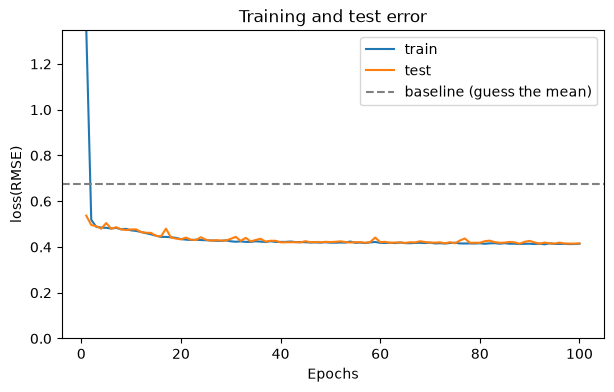

In [16]:
fig, ax = plt.subplots(figsize=(7, 4))

#plot train loss
ax.plot(range(1, EPOCHS + 1), train_losses, label='train')
# plot test losses
ax.plot(range(1, EPOCHS + 1), test_losses, label='test')

# this shows, again, guessing the mean train pH every time
ax.axhline(baseline_rmse, color='gray', linestyle='--', label='baseline (guess the mean)')
ax.set_ylim(0, 2 * baseline_rmse)   # zoom in: the first epochs start much higher
ax.set_xlabel('Epochs')
ax.set_ylabel('loss(RMSE)')
ax.set_title('Training and test error')
ax.legend()
plt.show()

## 3.2 - How do model predictions measure against true pH values?

Now we use the trained network to predict pH for every row of the test set, one batch at a time, and stitch the batches back together into one array. Because `test_loader` has `shuffle=False`, the predictions line up with `y_test` row for row.

In [17]:
# predict pH for the whole test set, batch by batch.
# Inside the loop, `X_batch` is one batch of test features. Append the model's
# predictions for that batch to the `preds` list. (You don't need the targets here, so
# the loop ignores them with `_`.)
# The last line glues all the batches into one numpy array.

model.eval()
preds = []
with torch.no_grad():
    for X_batch, _ in test_loader:
        preds.append(model(X_batch))    # model output for this X_batch

# stitch the batches together and convert to a 1D numpy array (done for you)
nn_preds = torch.cat(preds).squeeze().numpy()
print(nn_preds.shape)   # should match y_test.shape

(1671,)


In [18]:
# score the predictions against the true test-set pH values.
rmse = np.sqrt(mean_squared_error(y_test, nn_preds)) # true, then predicted
r2 = r2_score(y_test,nn_preds) # true, then predicted
print(f"RMSE: {rmse:.3f} pH units | R²: {r2:.3f}")
print(f"(baseline RMSE from always guessing the mean: {baseline_rmse:.3f})")

RMSE: 0.416 pH units | R²: 0.619
(baseline RMSE from always guessing the mean: 0.673)


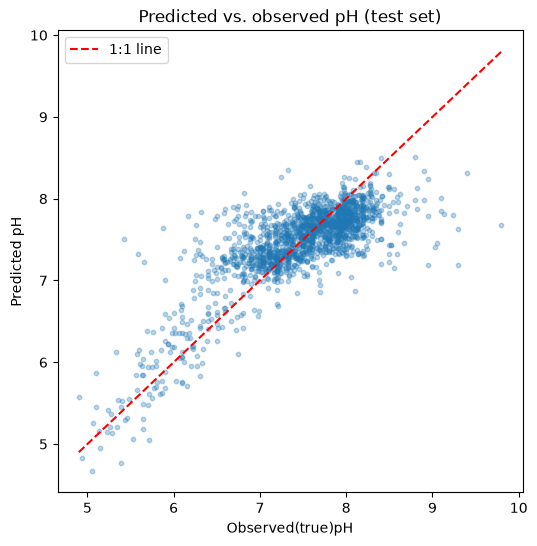

In [19]:
# scatter plot of observed vs. predicted pH, with a 1:1 reference line.

fig, ax = plt.subplots(figsize=(6, 6))
ax.scatter(y_test, nn_preds, alpha=0.3, s=10)    # (observed (true), predicted)

# 1:1 line (a perfect model would put every point on this line) -- done for you
lims = [y_test.min(), y_test.max()]
ax.plot(lims, lims, linestyle='--', color='red', label='1:1 line')

ax.set_xlabel('Observed(true)pH')
ax.set_ylabel('Predicted pH')
ax.set_title('Predicted vs. observed pH (test set)')
ax.legend()
plt.show()

## 3.3 - Where does the model go wrong? Residual plots

As before, let's examine the residuals of this model and visualize their distribution. The left histogram measures how distributed these residuals are about 0. If they are symmetric, this reveals little to no bias in our MLP. The right plot shows if there is any dependence of the residuals on true pH.


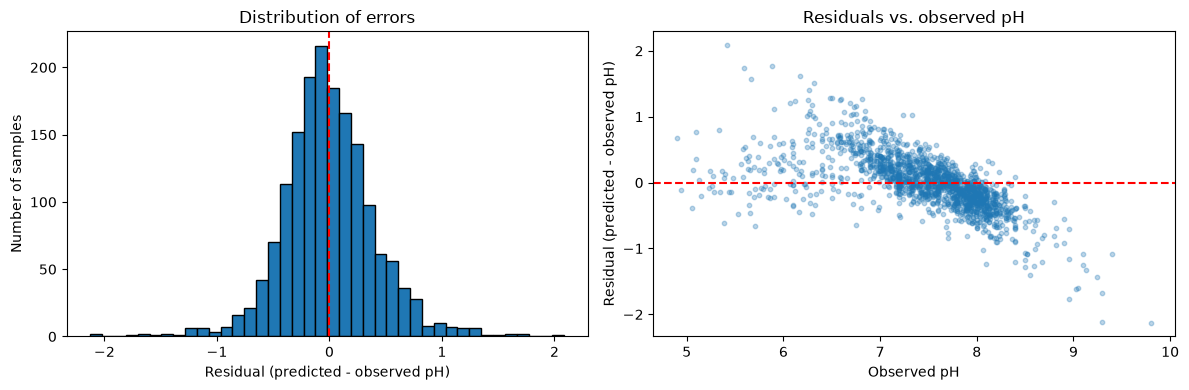

In [20]:
# compute residuals
residuals = nn_preds - y_test # predicted - observed in this case

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# left: distribution of errors
axes[0].hist(residuals, bins=40, edgecolor='black')
axes[0].axvline(0, color='red', linestyle='--')
axes[0].set_xlabel('Residual (predicted - observed pH)')
axes[0].set_ylabel('Number of samples')
axes[0].set_title('Distribution of errors')

# right: do the errors depend on the true pH?
axes[1].scatter(y_test, residuals, alpha=0.3, s=10)
axes[1].axhline(0, color='red', linestyle='--')
axes[1].set_xlabel('Observed pH')
axes[1].set_ylabel('Residual (predicted - observed pH)')
axes[1].set_title('Residuals vs. observed pH')

plt.tight_layout()
plt.show()

## Observation

In one or two sentences: does your network beat the "always guess the mean" baseline, and in what range of pH does it make its biggest errors?

*Answer*:Yes, the network beat the "always guess the mean" baseline, based on the early run test results the RMSE is reduce from 0.673 to 0.0415 pH with R2 0.619. As shown in plots the most residuals are centered near by 0, where models get errors at the end pH range (5-6.5) and after 8.2, where we see more scatter data.

## Optional: if you finish early

Picking **one thing at a time**, re-run from section 2.1 down, and see how the test RMSE changes:
- the hidden layer size (e.g. 4, 64, 128)
- the learning rate (e.g. 0.001, 0.05)
- add a second hidden layer to the `NeuralNetwork` class (another `nn.Linear` + `nn.ReLU`)

You do not need to do ALL of these, just one maybe.

## Mini-Evals (please fill out!!!)

1. Please rate 1-5 how this lab was for you. 1 := this was too difficult, 5 := I could do this in my sleep.

*Answer*: 2.5
 Most of this lab went over my head, hard to follow along with the steps.  

2. What is something you wished I covered in this lab?

*Answer*: It would be better if we spent more time to break the pytorch syntex step-by step and expain each variable and function one by one. Additinally, I wished if we had put more examples of how to interpret the loss curves and residual plots once the mode finished training.

Thank you to the TA for putting so much effort into designing this lab and working step-by-step in the pytorch syntex to make understandable for us in the class.

# Lab submission

Please `Restart` and `Run All` on this notebook and submit this lab when you are done!